# 01 Baseline models
Run cells from top to bottom. This notebook trains three seven-feature baselines using
the same grouped five-fold CV, displays evaluation metrics, ROC curves and confusion matrices,
and saves models/OOF results under a new run folder. No final test scoring is performed.


In [ ]:
# Optional: run once if the selected kernel lacks dependencies, then restart it.
# %pip install -r requirements-notebooks.txt

In [2]:
# Packages are already installed in the dedicated project kernel.
import sys
print("Kernel Python:", sys.executable)

Kernel Python: /Users/liujueshan/Desktop/comp4145/final project/.venv/bin/python


In [3]:
from pathlib import Path
import sys
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
import xgboost
from IPython.display import display
from sklearn.base import clone
from sklearn.exceptions import ConvergenceWarning
from sklearn.model_selection import cross_validate, GridSearchCV

# Set this only when Jupyter is launched outside the project.
PROJECT_ROOT = None  # Example: Path(r"/path/to/final project")
if PROJECT_ROOT is None:
    PROJECT_ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
                         if (p / "data/processed/cardio_train_80.csv").exists()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Set PROJECT_ROOT to the project folder containing data/ and predictive_analytics/.")
PROJECT_ROOT = Path(PROJECT_ROOT).expanduser().resolve()
NOTEBOOK_DIR = PROJECT_ROOT / "predictive_analytics"
sys.path.insert(0, str(NOTEBOOK_DIR))
from training_utils import (
    FEATURES, METRICS, SEED, MODEL_NAMES, load_development, build_pipeline,
    scorers, select_auc, begin_stage, collect_cv, save_model_result,
    finish_stage, load_stage, comparison_plots, compare_history,
)

# Use the SAME name in all three notebooks. Use a new name for a fresh rerun.
RUN_NAME = "seven_features_run_01"
RUN_DIR = NOTEBOOK_DIR / "runs" / RUN_NAME
print("Project:", PROJECT_ROOT)
print("Run output:", RUN_DIR)
print("scikit-learn:", sklearn.__version__, "| XGBoost:", xgboost.__version__)


Matplotlib is building the font cache; this may take a moment.


Project: /Users/liujueshan/Desktop/comp4145/final project
Run output: /Users/liujueshan/Desktop/comp4145/final project/predictive_analytics/runs/seven_features_run_01
scikit-learn: 1.9.1 | XGBoost: 3.4.1


Seven inputs: age, gender, BMI, systolic BP, diastolic BP, cholesterol and glucose.
Categorical encoding produces nine model columns. Logistic regression scales numeric inputs
inside each training fold; tree models do not scale them. The five grouped folds are identical
across models and stages. All classification metrics use `score >= 0.5`.

Tables report **five-fold validation means**. ROC/confusion plots use pooled out-of-fold (OOF)
predictions, so pooled AUC may differ slightly from the mean fold AUC.


In [4]:
# No test CSV is loaded. Continuous inputs are restored to original units.
ctx = load_development(PROJECT_ROOT)
X, y, cv = ctx["X"], ctx["y"], ctx["cv"]
assert X.shape == (54855, 7)
assert "cardio" not in FEATURES and "id" not in FEATURES
print("Input features:", FEATURES)
display(pd.DataFrame(X, columns=FEATURES).head())
display(pd.Series(y, name="cardio").value_counts().rename_axis("label").to_frame("records"))
display(pd.DataFrame([
    {"fold": i, "training_records": len(train), "validation_records": len(valid)}
    for i, (train, valid) in enumerate(cv, 1)
]))


Input features: ['age_years', 'gender', 'bmi', 'ap_hi', 'ap_lo', 'cholesterol', 'gluc']


,age_years,gender,bmi,ap_hi,ap_lo,cholesterol,gluc
0,59.890486,2.0,25.306932,120.0,80.0,1.0,1.0
1,57.746749,1.0,34.963580,135.0,90.0,2.0,1.0
2,42.187543,1.0,48.223448,180.0,120.0,2.0,1.0
3,49.744011,2.0,20.957274,80.0,70.0,1.0,1.0
4,57.549624,1.0,29.136316,120.0,90.0,2.0,1.0


,records
label,
0,27718
1,27137


,fold,training_records,validation_records
0,1,43884,10971
1,2,43883,10972
2,3,43885,10970
3,4,43884,10971
4,5,43884,10971


In [5]:
BASELINE_PARAMETERS = {
    "logistic_regression": {
        "C": 1.0, "solver": "lbfgs", "max_iter": 1000,
        "class_weight": None, "random_state": SEED,
    },
    "random_forest": {
        "n_estimators": 300, "max_depth": None, "min_samples_leaf": 1,
        "max_features": "sqrt", "max_samples": None, "bootstrap": True,
        "class_weight": None, "random_state": SEED, "n_jobs": 4,
    },
    "xgboost": {
        "n_estimators": 300, "max_depth": 3, "min_child_weight": 1,
        "learning_rate": 0.05, "subsample": 1.0, "colsample_bytree": 1.0,
        "reg_lambda": 1.0, "objective": "binary:logistic",
        "eval_metric": "logloss", "tree_method": "hist",
        "random_state": SEED, "n_jobs": 4,
    },
}
baseline_table = pd.DataFrame([
    {"Model": name, "Parameter": key, "Value": repr(value)}
    for name, parameters in BASELINE_PARAMETERS.items()
    for key, value in parameters.items()
])
display(baseline_table.style.hide(axis='index').set_properties(**{'text-align': 'left', 'white-space': 'normal', 'overflow-wrap': 'anywhere'}))
STAGE_DIR = begin_stage(RUN_DIR, "01_baseline", ctx)
SCORING = scorers()
results = {}


Model,Parameter,Value
logistic_regression,C,1.0
logistic_regression,solver,'lbfgs'
logistic_regression,max_iter,1000
logistic_regression,class_weight,None
logistic_regression,random_state,4145
random_forest,n_estimators,300
random_forest,max_depth,None
random_forest,min_samples_leaf,1
random_forest,max_features,'sqrt'
random_forest,max_samples,None


## Train and evaluate the baselines
Each model has five development-fold fits, followed by one full-development refit.
Fold training scores diagnose overfitting; validation scores evaluate held-out fold records.


In [6]:
for name, parameters in BASELINE_PARAMETERS.items():
    print("Training baseline:", MODEL_NAMES[name], flush=True)
    pipeline = build_pipeline(name, parameters)
    with warnings.catch_warnings():
        warnings.simplefilter("error", ConvergenceWarning)
        cv_result = cross_validate(
            pipeline, X, y, cv=cv, scoring=SCORING,
            return_train_score=True, return_estimator=True,
            n_jobs=1, error_score="raise",
        )
    evaluation = collect_cv(cv_result["estimator"], ctx)
    display(evaluation["fold_metrics"].round(6))

    # This saved model uses all development records, not any final test records.
    final_model = clone(pipeline)
    with warnings.catch_warnings():
        warnings.simplefilter("error", ConvergenceWarning)
        final_model.fit(X, y)
    save_model_result(STAGE_DIR, name, final_model, parameters, evaluation, ctx)
    results[name] = evaluation
    print("Validation mean:", evaluation["summary"])
    del cv_result

comparison = finish_stage(STAGE_DIR, ctx, BASELINE_PARAMETERS)


Training baseline: Logistic Regression


,fold,training_records,validation_records,train_roc_auc,train_accuracy,train_precision,train_recall,train_f1,train_specificity,train_average_precision,...,accuracy,precision,recall,f1,specificity,average_precision,tn,fp,fn,tp
0,1,43884,10971,0.791010,0.727851,0.757474,0.661769,0.706394,0.792550,0.769114,...,0.726005,0.754467,0.661323,0.704831,0.789322,0.772943,4376,1168,1838,3589
1,2,43883,10972,0.791041,0.727412,0.756730,0.661707,0.706036,0.791738,0.770204,...,0.727853,0.752481,0.670413,0.709080,0.784091,0.767135,4347,1197,1789,3639
2,3,43885,10970,0.791038,0.726991,0.756013,0.661677,0.705706,0.790936,0.770079,...,0.731905,0.763459,0.663718,0.710103,0.798665,0.769368,4427,1116,1825,3602
3,4,43884,10971,0.790875,0.727167,0.755753,0.662628,0.706134,0.790349,0.768821,...,0.729560,0.762871,0.657885,0.706499,0.799747,0.773694,4433,1110,1857,3571
4,5,43884,10971,0.791925,0.728671,0.758314,0.662782,0.707337,0.793181,0.770692,...,0.722632,0.751159,0.656901,0.700875,0.786977,0.765830,4363,1181,1862,3565


Validation mean: {'roc_auc': 0.7910570387341062, 'accuracy': 0.7275909953965907, 'precision': 0.7568875271055316, 'recall': 0.6620479713390253, 'f1': 0.706277782295255, 'specificity': 0.7917604044881692, 'average_precision': 0.7697939134557787, 'training_accuracy': 0.7276182682550675, 'training_auc': 0.7911777361291282}
Training baseline: Random Forest


,fold,training_records,validation_records,train_roc_auc,train_accuracy,train_precision,train_recall,train_f1,train_specificity,train_average_precision,...,accuracy,precision,recall,f1,specificity,average_precision,tn,fp,fn,tp
0,1,43884,10971,1.0,0.999749,0.999770,0.999724,0.999747,0.999775,1.0,...,0.704767,0.703270,0.697439,0.700342,0.711941,0.744396,3947,1597,1642,3785
1,2,43883,10972,1.0,0.999727,0.999678,0.999770,0.999724,0.999684,1.0,...,0.704521,0.704758,0.693073,0.698867,0.715729,0.742881,3968,1576,1666,3762
2,3,43885,10970,1.0,0.999681,0.999816,0.999539,0.999678,0.999820,1.0,...,0.704102,0.703641,0.694306,0.698943,0.713693,0.745499,3956,1587,1659,3768
3,4,43884,10971,1.0,0.999749,0.999908,0.999585,0.999747,0.999910,1.0,...,0.704676,0.704639,0.693994,0.699276,0.715136,0.751825,3964,1579,1661,3767
4,5,43884,10971,1.0,0.999658,0.999862,0.999447,0.999654,0.999865,1.0,...,0.706043,0.708998,0.688226,0.698457,0.723485,0.749808,4011,1533,1692,3735


Validation mean: {'roc_auc': 0.7639780710049007, 'accuracy': 0.7048217953057831, 'precision': 0.7050613314685131, 'recall': 0.6934075154943914, 'f1': 0.6991770100765832, 'specificity': 0.7159967110084375, 'average_precision': 0.7468820337429365, 'training_accuracy': 0.9997128796169956, 'training_auc': 0.9999997982957675}
Training baseline: XGBoost


,fold,training_records,validation_records,train_roc_auc,train_accuracy,train_precision,train_recall,train_f1,train_specificity,train_average_precision,...,accuracy,precision,recall,f1,specificity,average_precision,tn,fp,fn,tp
0,1,43884,10971,0.807219,0.739222,0.758433,0.693874,0.724719,0.783620,0.795488,...,0.736669,0.755332,0.691727,0.722131,0.780664,0.784078,4328,1216,1673,3754
1,2,43883,10972,0.807554,0.739124,0.759313,0.692017,0.724105,0.785244,0.795380,...,0.736055,0.752191,0.695652,0.722818,0.775613,0.781461,4300,1244,1652,3776
2,3,43885,10970,0.807271,0.739387,0.758883,0.693551,0.724748,0.784262,0.795118,...,0.740109,0.760518,0.692832,0.725099,0.786397,0.779145,4359,1184,1667,3760
3,4,43884,10971,0.806768,0.738925,0.755152,0.698835,0.725903,0.778174,0.793311,...,0.734117,0.752260,0.689757,0.719654,0.777557,0.786337,4310,1233,1684,3744
4,5,43884,10971,0.807025,0.739746,0.756827,0.698296,0.726384,0.780328,0.795319,...,0.732294,0.749799,0.688594,0.717895,0.775072,0.777180,4297,1247,1690,3737


Validation mean: {'roc_auc': 0.8005388703203071, 'accuracy': 0.7358491305072548, 'precision': 0.7540201564279331, 'recall': 0.6917123490329677, 'f1': 0.7215193057248869, 'specificity': 0.7790607487206801, 'average_precision': 0.7816404397159469, 'training_accuracy': 0.7392808300859348, 'training_auc': 0.807167347172699}


## Compare the three baseline models


In [7]:
display(comparison[[
    "model", "status", "training_auc", "roc_auc", "training_accuracy",
    "accuracy", "precision", "recall", "f1", "specificity", "average_precision"
]].round(6))


,model,status,training_auc,roc_auc,training_accuracy,accuracy,precision,recall,f1,specificity,average_precision
0,logistic_regression,trained,0.791178,0.791057,0.727618,0.727591,0.756888,0.662048,0.706278,0.791760,0.769794
1,random_forest,trained,1.000000,0.763978,0.999713,0.704822,0.705061,0.693408,0.699177,0.715997,0.746882
2,xgboost,trained,0.807167,0.800539,0.739281,0.735849,0.754020,0.691712,0.721519,0.779061,0.781640


## Baseline training versus validation ROC-AUC
Mean training and validation AUC across the same five development folds.


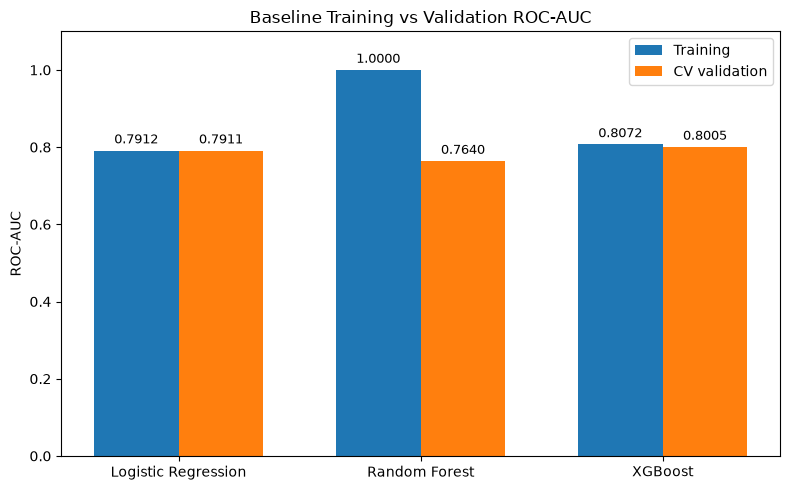

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Use the completed baseline results; this cell does not retrain the models.
if "RUN_DIR" in globals():
    auc_stage_dir = Path(RUN_DIR) / "01_baseline"
else:
    root = next(p for p in [Path.cwd(), *Path.cwd().parents]
                if (p / "predictive_analytics").is_dir())
    auc_stage_dir = (root / "predictive_analytics/runs"
                     / globals().get("RUN_NAME", "seven_features_run_01") / "01_baseline")

auc_table = pd.read_csv(auc_stage_dir / "model_comparison.csv").set_index("model")
auc_table = auc_table.loc[["logistic_regression", "random_forest", "xgboost"]]
x = np.arange(3)
width = 0.35

fig, ax = plt.subplots(figsize=(8, 5))
train_bars = ax.bar(x - width / 2, auc_table["training_auc"], width, label="Training")
validation_bars = ax.bar(x + width / 2, auc_table["roc_auc"], width, label="CV validation")
ax.bar_label(train_bars, fmt="%.4f", padding=3, fontsize=9)
ax.bar_label(validation_bars, fmt="%.4f", padding=3, fontsize=9)
ax.set_xticks(x, ["Logistic Regression", "Random Forest", "XGBoost"])
ax.set_ylabel("ROC-AUC")
ax.set_title("Baseline Training vs Validation ROC-AUC")
ax.set_ylim(0, 1.1)
ax.set_yticks(np.arange(0, 1.01, 0.2))
ax.legend()
fig.tight_layout()
fig.savefig(auc_stage_dir / "baseline_training_vs_validation_auc.png", dpi=160)
fig.savefig(auc_stage_dir / "baseline_training_vs_validation_auc.svg")
plt.show()


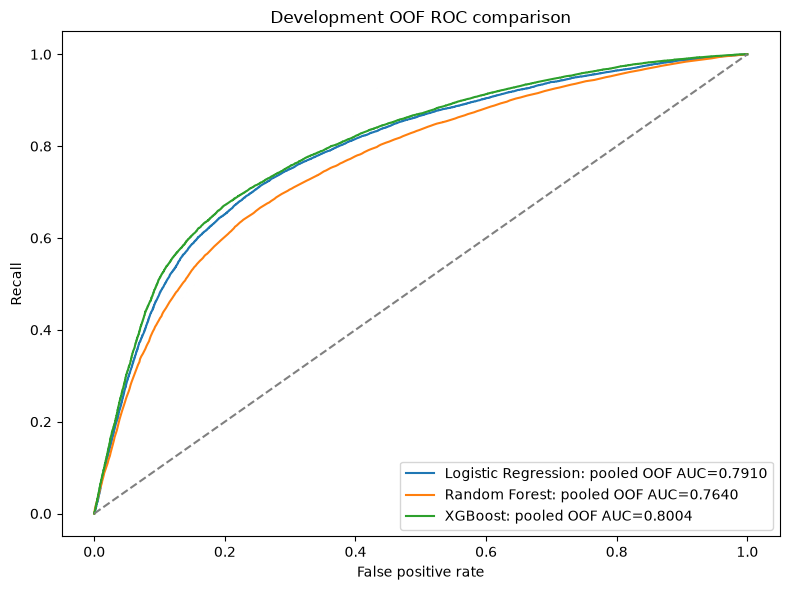

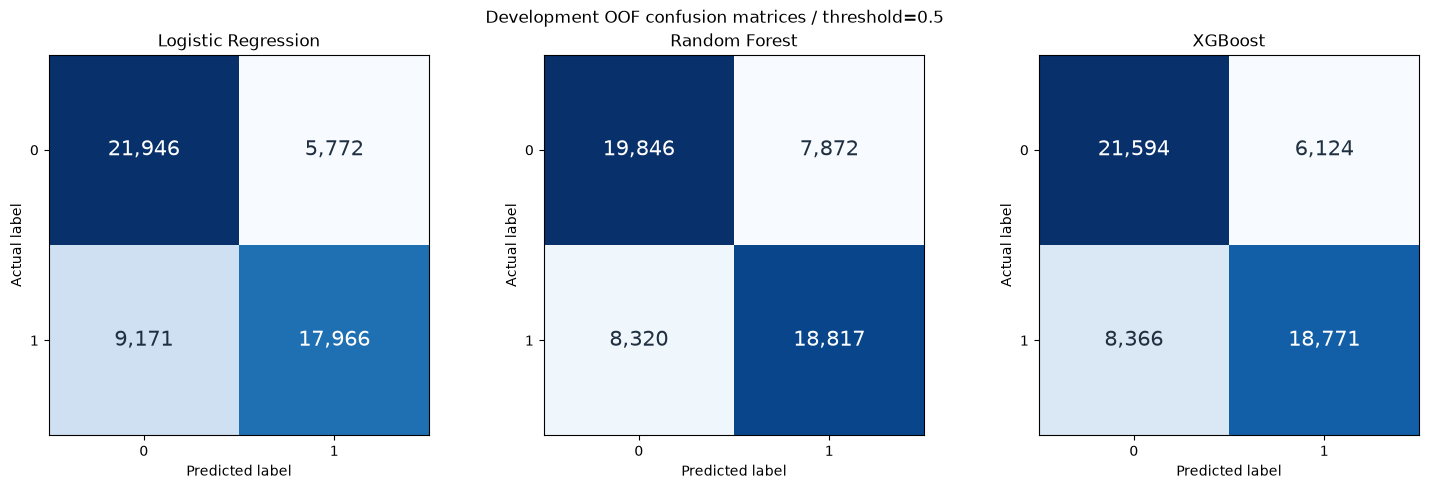

In [8]:
# Models trained on each validation record's own training fold generated these scores.
# The separately saved final model is fitted on all development records.
comparison_plots(results, ctx, STAGE_DIR)


In [9]:
history = compare_history(RUN_DIR, ["01_baseline"])
print("Saved baseline output:", STAGE_DIR)
print("Next: open 02_optimization_round1.ipynb with the same RUN_NAME.")


Saved baseline output: /Users/liujueshan/Desktop/comp4145/final project/predictive_analytics/runs/seven_features_run_01/01_baseline
Next: open 02_optimization_round1.ipynb with the same RUN_NAME.
